In [1]:
import os
from pathlib import Path

ROOT_DIR = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
processed_dir = ROOT_DIR / 'data' / 'dogs-vs-cats-processed'
for split in ['train', 'validation', 'test']:
    cats_cnt = len(list((processed_dir / split / 'cats').glob('*.jpg')))
    dogs_cnt = len(list((processed_dir / split / 'dogs').glob('*.jpg')))
    print(f'{split:<12}: Коти = {cats_cnt:<5} | Собаки = {dogs_cnt:<5} | Разом = {cats_cnt + dogs_cnt}')

train       : Коти = 10000 | Собаки = 10000 | Разом = 20000
validation  : Коти = 1250  | Собаки = 1250  | Разом = 2500
test        : Коти = 1250  | Собаки = 1250  | Разом = 2500


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

train_datagen = ImageDataGenerator(rescale=1/255.0)
val_datagen = ImageDataGenerator(rescale=1/255.0)
test_datagen = ImageDataGenerator(rescale=1/255.0)

train_gen = train_datagen.flow_from_directory(
    str(ROOT_DIR / 'data' / 'dogs-vs-cats-processed' / 'train'),
    target_size=(150, 150),
    batch_size=64,
    class_mode='binary',
    shuffle=True
)

val_gen = val_datagen.flow_from_directory(
    str(ROOT_DIR / 'data' / 'dogs-vs-cats-processed' / 'validation'),
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    str(ROOT_DIR / 'data' / 'dogs-vs-cats-processed' / 'test'),
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 20000 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.


In [3]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer=RMSprop(learning_rate=0.001),
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    train_gen,
    steps_per_epoch=50,
    epochs=15,
    validation_data=val_gen,
    validation_steps=25,
    verbose=1
)

model_path = ROOT_DIR / 'models' / 'dogs_vs_cats_model.keras'
model.save(str(model_path))
print(f'Модель збережено в: {model_path}')

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 481ms/step - accuracy: 0.5147 - loss: 0.7028 - val_accuracy: 0.5700 - val_loss: 0.6923
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 527ms/step - accuracy: 0.5469 - loss: 0.6858 - val_accuracy: 0.9962 - val_loss: 0.4919
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 556ms/step - accuracy: 0.5533 - loss: 0.6880 - val_accuracy: 0.7075 - val_loss: 0.6636
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 36s 716ms/step - accuracy: 0.5962 - loss: 0.6601 - val_accuracy: 0.4150 - val_loss: 0.8059
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 545ms/step - accuracy: 0.6194 - loss: 0.6425 - val_accuracy: 0.5638 - val_loss: 0.6810
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 536ms/step - accuracy: 0.6544 - loss: 0.6151 - val_accuracy: 0.6288 - val_loss: 0.6059
Epoch 7/15
13/50 ━━━━━━━━━━━━━━━━━━━━ 19s 530ms/step - accuracy: 0.6767 - loss: 0.6030

/Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab7/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 168ms/step - accuracy: 0.6767 - loss: 0.6030 - val_accuracy: 0.9500 - val_loss: 0.3530
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 541ms/step - accuracy: 0.6722 - loss: 0.6040 - val_accuracy: 0.3487 - val_loss: 0.8662
Epoch 9/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 33s 654ms/step - accuracy: 0.7022 - loss: 0.5844 - val_accuracy: 0.1037 - val_loss: 1.1332
Epoch 10/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 573ms/step - accuracy: 0.6953 - loss: 0.5739 - val_accuracy: 0.8612 - val_loss: 0.4564
Epoch 11/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 560ms/step - accuracy: 0.7393 - loss: 0.5300 - val_accuracy: 0.9150 - val_loss: 0.3203
Epoch 12/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 578ms/step - accuracy: 0.7325 - loss: 0.5367 - val_accuracy: 0.5000 - val_loss: 0.7960
Epoch 13/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 579ms/step - accuracy: 0.7431 - loss: 0.5236 - val_accuracy: 0.8138 - val_loss: 0.4297
Epoch 14/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 173ms/step - accuracy: 0.7716 - loss: 0.5029 - val_accuracy: 0.

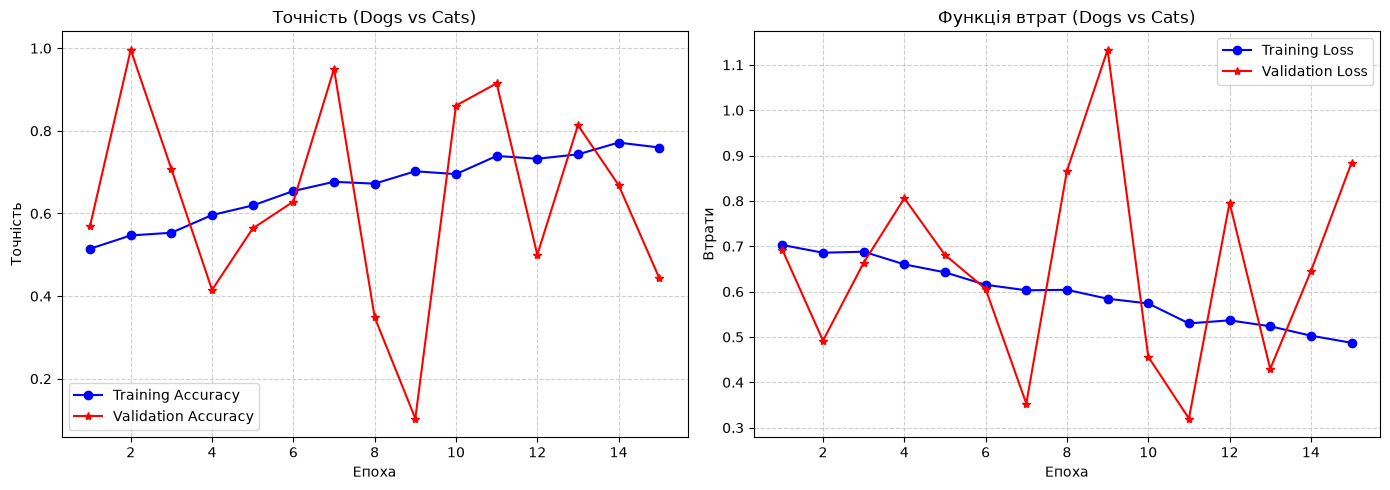

In [5]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'r*-', label='Validation Accuracy')
plt.title('Точність (Dogs vs Cats)')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'bo-', label='Training Loss')
plt.plot(epochs_range, val_loss, 'r*-', label='Validation Loss')
plt.title('Функція втрат (Dogs vs Cats)')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.6796 - loss: 0.5796
Тестові втрати (Loss): 0.5796
Тестова точність (Accuracy): 67.96%
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step


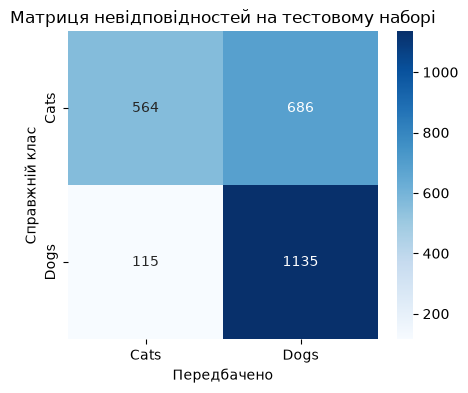

In [6]:
test_eval = model.evaluate(test_gen, verbose=1)
print(f'Тестові втрати (Loss): {test_eval[0]:.4f}')
print(f'Тестова точність (Accuracy): {test_eval[1]*100:.2f}%')

test_preds = model.predict(test_gen, verbose=1)
test_preds_binary = (test_preds > 0.5).astype(int).flatten()
cm = confusion_matrix(test_gen.classes, test_preds_binary)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Cats', 'Dogs'], yticklabels=['Cats', 'Dogs'])
plt.title('Матриця невідповідностей на тестовому наборі')
plt.xlabel('Передбачено')
plt.ylabel('Справжній клас')
plt.show()

In [7]:
from pathlib import Path

def test_custom_folder(folder_path, expected_label):
    folder_path = Path(folder_path)
    files = sorted(list(folder_path.glob('*.jpg')))
    correct = 0
    print(f'=== Тестування вибірки: {expected_label} ===')
    for p in files:
        img = image.load_img(p, target_size=(150, 150))
        x = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)
        prob = float(model.predict(x, verbose=0)[0][0])
        pred_cls = 'Собака' if prob > 0.5 else 'Кіт'
        conf = prob if prob > 0.5 else 1.0 - prob
        is_ok = (pred_cls == expected_label)
        if is_ok: correct += 1
        print(f'{p.name:<12} -> {pred_cls} ({conf*100:.1f}%) [Вірно: {is_ok}]')
    print(f'Точність на вибірці {expected_label}: {correct}/{len(files)} ({correct/len(files)*100:.1f}%)\n')

test_custom_folder(ROOT_DIR / 'test_images' / 'custom_cats', 'Кіт')
test_custom_folder(ROOT_DIR / 'test_images' / 'custom_dogs', 'Собака')

=== Тестування вибірки: Кіт ===
cat_01.jpg   -> Собака (57.6%) [Вірно: False]
cat_02.jpg   -> Собака (90.3%) [Вірно: False]
cat_03.jpg   -> Кіт (70.4%) [Вірно: True]
cat_04.jpg   -> Собака (81.2%) [Вірно: False]
cat_05.jpg   -> Кіт (64.1%) [Вірно: True]
cat_06.jpg   -> Собака (92.5%) [Вірно: False]
cat_07.jpg   -> Кіт (55.1%) [Вірно: True]
cat_08.jpg   -> Кіт (59.9%) [Вірно: True]
cat_09.jpg   -> Кіт (54.9%) [Вірно: True]
cat_10.jpg   -> Собака (77.5%) [Вірно: False]
Точність на вибірці Кіт: 5/10 (50.0%)

=== Тестування вибірки: Собака ===
dog_01.jpg   -> Собака (57.2%) [Вірно: True]
dog_02.jpg   -> Собака (90.3%) [Вірно: True]
dog_03.jpg   -> Собака (96.7%) [Вірно: True]
dog_04.jpg   -> Собака (58.0%) [Вірно: True]
dog_05.jpg   -> Собака (90.9%) [Вірно: True]
dog_06.jpg   -> Собака (81.9%) [Вірно: True]
dog_07.jpg   -> Собака (81.3%) [Вірно: True]
dog_08.jpg   -> Собака (97.3%) [Вірно: True]
dog_09.jpg   -> Собака (91.5%) [Вірно: True]
dog_10.jpg   -> Собака (60.1%) [Вірно: True]
Точн

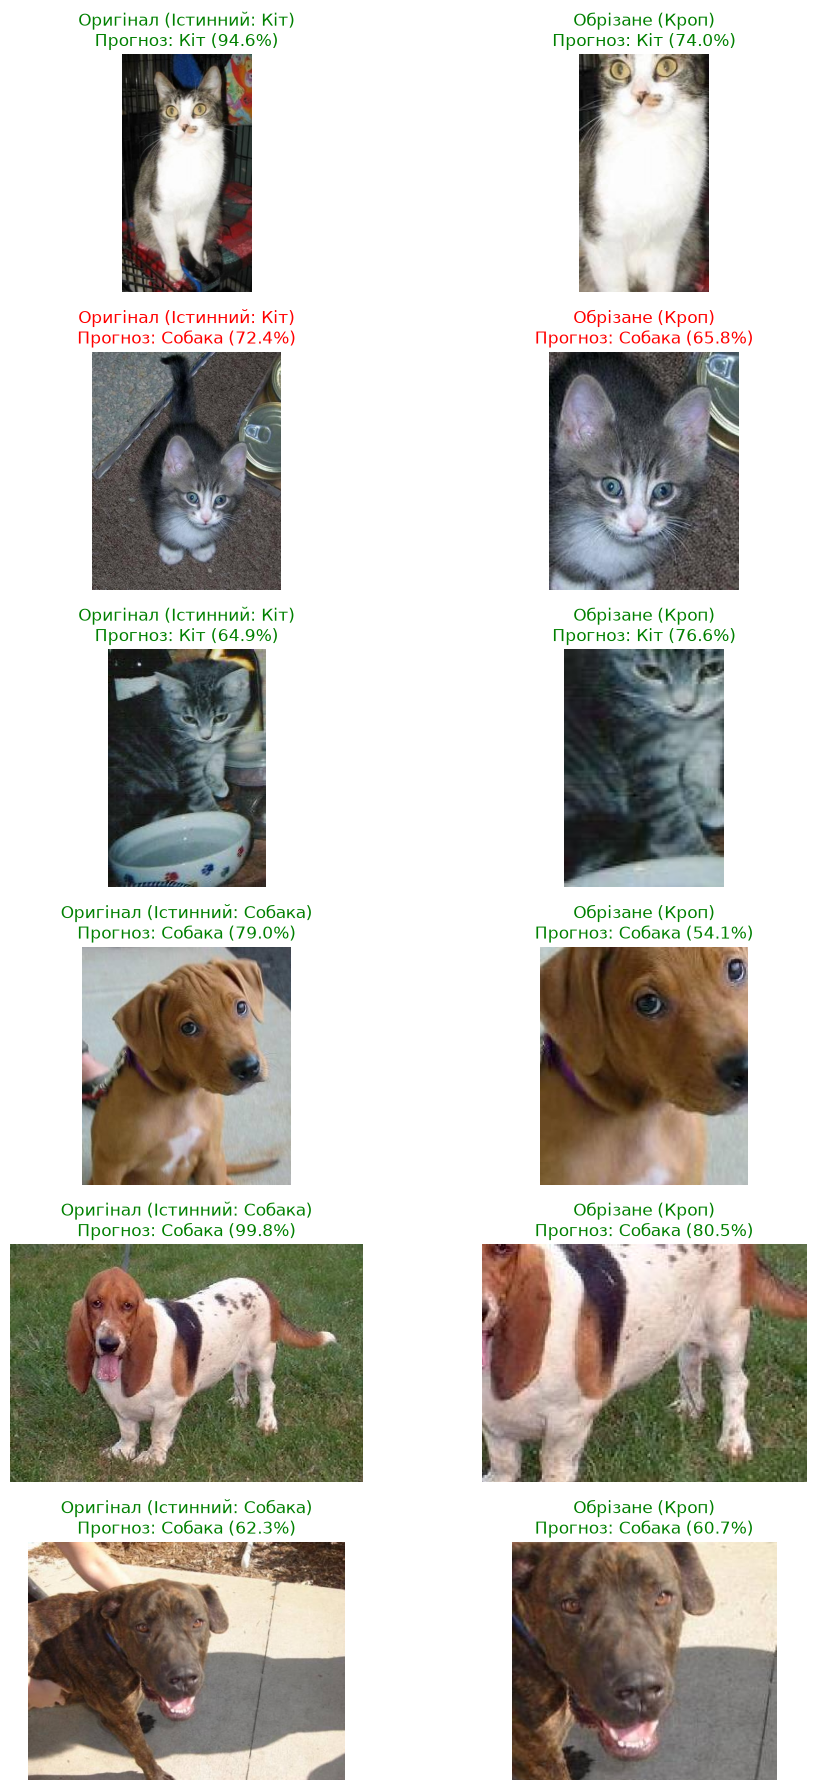

In [8]:
from pathlib import Path

raw_dir = ROOT_DIR / 'test_images' / 'raw'
crop_dir = ROOT_DIR / 'test_images' / 'cropped'
raw_files = sorted(list(raw_dir.glob('*.jpg')))

fig, axes = plt.subplots(len(raw_files), 2, figsize=(10, 3 * len(raw_files)))

for idx, rf in enumerate(raw_files):
    cf = crop_dir / rf.name.replace('.jpg', '_cropped.jpg')
    true_cls = 'Кіт' if 'cat' in rf.name else 'Собака'
    
    img_r = image.load_img(rf, target_size=(150, 150))
    xr = np.expand_dims(image.img_to_array(img_r)/255.0, axis=0)
    pr = float(model.predict(xr, verbose=0)[0][0])
    pred_r = 'Собака' if pr > 0.5 else 'Кіт'
    conf_r = pr if pr > 0.5 else 1.0 - pr
    ok_r = (pred_r == true_cls)
    
    img_c = image.load_img(cf, target_size=(150, 150))
    xc = np.expand_dims(image.img_to_array(img_c)/255.0, axis=0)
    pc = float(model.predict(xc, verbose=0)[0][0])
    pred_c = 'Собака' if pc > 0.5 else 'Кіт'
    conf_c = pc if pc > 0.5 else 1.0 - pc
    ok_c = (pred_c == true_cls)
    
    axes[idx, 0].imshow(Image.open(rf))
    axes[idx, 0].set_title(f'Оригінал (Істинний: {true_cls})\nПрогноз: {pred_r} ({conf_r*100:.1f}%)',
                           color='green' if ok_r else 'red')
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(Image.open(cf))
    axes[idx, 1].set_title(f'Обрізане (Кроп)\nПрогноз: {pred_c} ({conf_c*100:.1f}%)',
                           color='green' if ok_c else 'red')
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()